# M7: Weighted network analysis

**Paper section covered:** none: this is the first milestone of Part B (work the paper does not do). It addresses the paper's own "future work" ("with a weighted edge we can have more insight into the traffic distribution and importance of the node") and the codeshare caveat found in M0.

## The gap
The paper builds an edge weight (the number of route rows between two airports) and then **never uses it**: every metric, every ranking and every attack in Sections 3 to 5 is unweighted (confirmed in M1). Yet weights are the only information in the data about how *much* service each connection carries. And M0 showed the weight is partly an artefact: 44% of the underlying route rows are **codeshare listings**, and 715 of the 2,780 edges (26%) have no operating-carrier row at all.

## Goals
1. Understand what the weights contain and what the codeshare listings do to them.
2. Redo the paper's measures with weights and see whether the answer to "which airports matter most?" changes.
3. Redo the attack experiment with **weighted strategies** and with a damage measure in **service units** rather than airport counts.
4. Test whether the paper's headline conclusions survive when the doubtful (codeshare-only) edges are removed.

## Two weightings (a lower and an upper bound)
| Network | Edges counted | Weight |
|---|---|---|
| **Paper network** `G` | every domestic route row | rows per airport pair (includes codeshare listings): an *upper bound* on real service |
| **Operated-only network** `G_op` | only rows *not* marked codeshare | operating rows per pair: a *lower bound*, since OpenFlights sometimes lists a route only once, under the marketing carrier |

The truth lies between the two, so conclusions that hold on **both** are robust.

## Plan
| Part | Content |
|---|---|
| A | What the weights look like; what codeshare listings do |
| B | Weighted centralities and rankings: does the most critical airport change? |
| C | Weighted attacks and a service-based damage measure |
| D | Do the paper's conclusions survive on the operated-only network? |
| E | Verdict |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau
from sklearn.metrics import normalized_mutual_info_score as nmi

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, weighted as wt, attacks as at, communities as cm, nullmodels as nm, cascade as cs, powerlaw_tools as pt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 175)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE, TEAL, BROWN = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2", "#17a2b8", "#8c564b"

airports, routes = usfn.load_openflights()
G0 = usfn.build_country_network(airports, routes)
G, Gop, cshare = wt.build_weightings(G0, routes)
nodes = list(G.nodes); N = len(nodes)
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in nodes}
assert (N, G.number_of_edges()) == (541, 2780)
W_all = sum(d["weight"] for *_, d in G.edges(data=True)); W_op = sum(d["weight"] for *_, d in Gop.edges(data=True))
rng = np.random.default_rng(2025)
print(f"paper network G: {N} airports, {G.number_of_edges()} edges, total weight {W_all}")
print(f"operated-only G_op: {Gop.number_of_nodes()} airports, {Gop.number_of_edges()} edges, total weight {W_op}")

paper network G: 541 airports, 2780 edges, total weight 10507
operated-only G_op: 446 airports, 2065 edges, total weight 5884


## Part A. What do the weights contain?

### A1. The two networks side by side

In [2]:
lost = [n for n in nodes if n not in Gop]
ak = {n for n in nodes if pos[n][1] > 50}
w_all = np.array([d["weight"] for *_, d in G.edges(data=True)]); w_op = np.array([d["weight"] for *_, d in Gop.edges(data=True)])
comp = pd.DataFrame({
    "airports": [N, Gop.number_of_nodes()], "edges": [G.number_of_edges(), Gop.number_of_edges()], "total weight (route rows)": [W_all, W_op],
    "median edge weight": [np.median(w_all), np.median(w_op)], "heaviest edge": [w_all.max(), w_op.max()],
    "edges with weight 1": [f"{(w_all == 1).mean():.1%}", f"{(w_op == 1).mean():.1%}"]}, index=["paper network G (all rows)", "operated-only G_op"])
display(comp)

dl = pd.Series([G.degree(n) for n in lost])
print(f"{len(lost)} airports ({len(lost) / N:.0%}) appear only in codeshare listings and vanish from G_op")
print(f"   their degree in G: mean {dl.mean():.1f}, maximum {dl.max()}; in Alaska: {sum(n in ak for n in lost)}; largest examples: {', '.join(sorted(lost, key=lambda n: -G.degree(n))[:8])}")
print(f"codeshare rows are {1 - W_op / W_all:.0%} of all domestic route rows")

,airports,edges,total weight (route rows),median edge weight,heaviest edge,edges with weight 1
paper network G (all rows),541,2780,10507,3.0,39,3.6%
operated-only G_op,446,2065,5884,2.0,16,6.6%


95 airports (18%) appear only in codeshare listings and vanish from G_op
   their degree in G: mean 1.7, maximum 6; in Alaska: 15; largest examples: RDM, BFL, HLN, STS, LWS, HPB, VAK, SCM
codeshare rows are 44% of all domestic route rows


So the operated-only network keeps 82% of the airports and 74% of the edges but only 56% of the weight. The airports lost are very small (mean degree 1.7, at most 6 connections): places reached only by flights that OpenFlights marks as codeshare. This is why `G_op` is a *lower bound* (some of those flights are real) and `G` an *upper bound*.

### A2. What does the weight structure look like?
Three standard questions about weighted networks: how does an airport's total weight (**strength**) grow with its number of connections (degree)? Do heavy edges join big airports? Is an airport's weight spread evenly over its edges (**disparity**)?

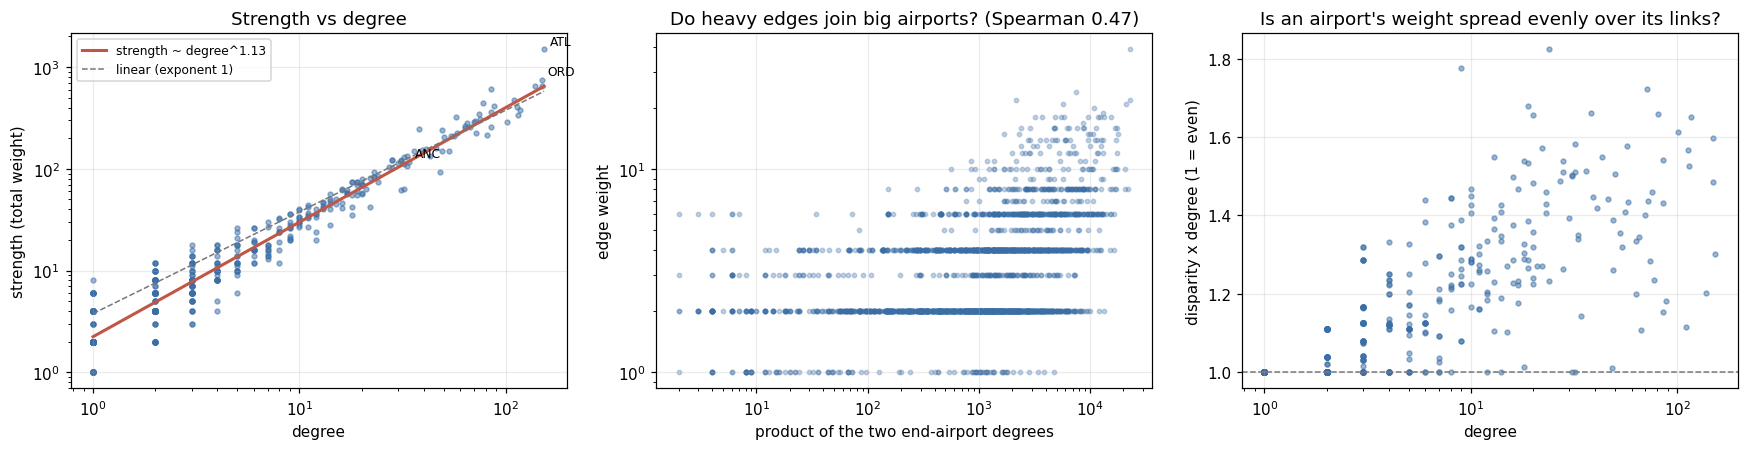

strength ~ degree^1.13  (exponent above 1: big airports carry disproportionately heavy edges)
median disparity x degree: 1.01 overall; 1.42 for airports with degree >= 50


In [3]:
deg = dict(G.degree()); strength = dict(G.degree(weight="weight"))
d = np.array([deg[n] for n in nodes]); s = np.array([strength[n] for n in nodes])
beta, a0 = np.polyfit(np.log(d), np.log(s), 1)

Y2 = {}                                                              # disparity: sum of squared weight shares; times degree = 1 if weights are evenly spread
for n in nodes:
    ws = np.array([G[n][m]["weight"] for m in G.neighbors(n)]); Y2[n] = np.sum((ws / ws.sum()) ** 2)
y2k = np.array([Y2[n] * deg[n] for n in nodes])

eu = np.array([deg[u] * deg[v] for u, v in G.edges]); ew = np.array([G[u][v]["weight"] for u, v in G.edges])
rho_w = spearmanr(eu, ew).statistic

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]; ax.scatter(d, s, s=10, alpha=0.5, color=BLUE); kk = np.array([1, d.max()]); ax.plot(kk, np.exp(a0) * kk ** beta, color=RED, lw=2, label=f"strength ~ degree^{beta:.2f}")
ax.plot(kk, np.exp(a0) * kk ** 1.0 * (s.mean() / d.mean() / np.exp(a0)) , color=GREY, ls="--", lw=1, label="linear (exponent 1)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("degree"); ax.set_ylabel("strength (total weight)"); ax.set_title("Strength vs degree"); ax.legend(fontsize=8)
for n in ["ATL", "ORD", "ANC"]: ax.annotate(n, (deg[n], strength[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax = axes[1]; ax.scatter(eu, ew, s=8, alpha=0.3, color=BLUE); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("product of the two end-airport degrees"); ax.set_ylabel("edge weight"); ax.set_title(f"Do heavy edges join big airports? (Spearman {rho_w:.2f})")
ax = axes[2]; ax.scatter(d, y2k, s=10, alpha=0.5, color=BLUE); ax.axhline(1, color=GREY, ls="--", lw=1); ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel("disparity x degree (1 = even)"); ax.set_title("Is an airport's weight spread evenly over its links?")
plt.tight_layout(); plt.show()
print(f"strength ~ degree^{beta:.2f}  (exponent above 1: big airports carry disproportionately heavy edges)")
print(f"median disparity x degree: {np.median(y2k):.2f} overall; {np.median(y2k[d >= 50]):.2f} for airports with degree >= 50")

**Reading this.** Strength grows slightly faster than degree (exponent about 1.13), so big airports have *heavier* edges, not just more of them; heavy edges tend to join big airports (Spearman 0.47 between edge weight and the product of the end-airport degrees); and an airport's weight is spread about evenly over its links overall (median disparity x degree 1.01) but is **concentrated at hubs** (median 1.42 for airports with degree 50 or more). So weights do carry information that the unweighted analysis throws away.

### A3. What do codeshare listings do to the picture?
The paper's weight counts every airline that lists a pair, including marketing partners. Airlines with many codeshare partners (Delta and its Skyteam partners, American and its oneworld partners) have their hubs inflated; an airline that does not codeshare (Southwest) does not. We compare each airport's strength under the two weightings.

airport,strength (paper),strength (operated),codeshare share of rows,rank (paper),rank (operated),operated / paper
ATL,1496,418,0.72,1,2,0.28
ORD,752,341,0.55,2,5,0.45
DFW,657,454,0.31,3,1,0.69
DEN,653,405,0.38,4,3,0.62
LAX,606,326,0.46,5,8,0.54
CLT,477,371,0.22,6,4,0.78
PHX,441,330,0.25,7,7,0.75
PHL,412,271,0.34,8,9,0.66
LAS,404,336,0.17,9,6,0.83
MSP,380,206,0.46,10,13,0.54


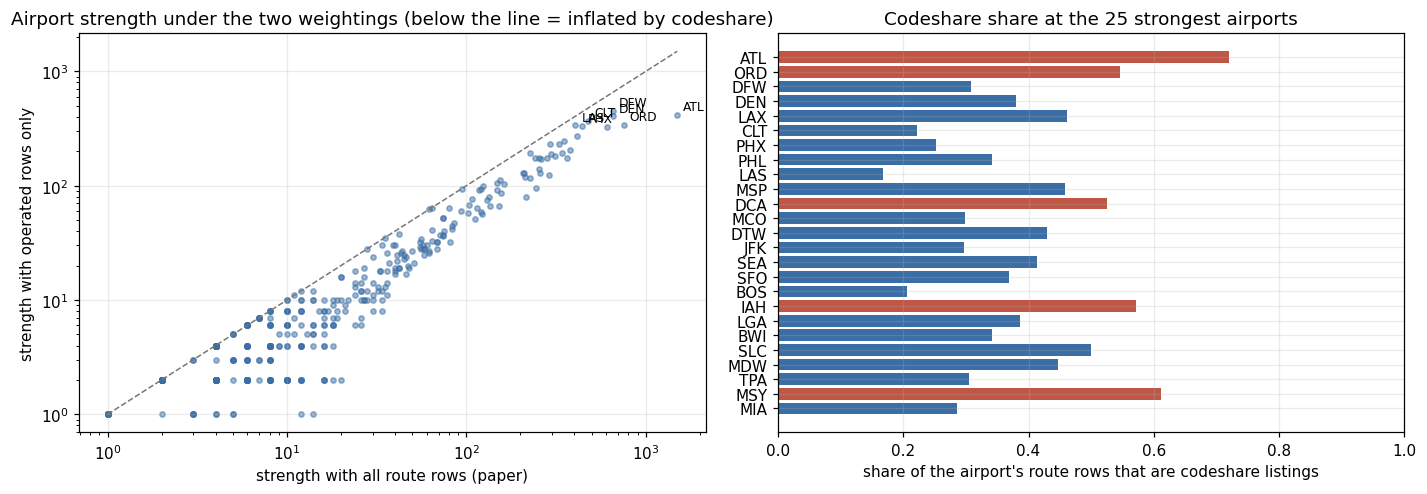

correlation between the two strengths (Spearman, airports in both): 0.90


In [4]:
s_op = dict(Gop.degree(weight="weight"))
tab = pd.DataFrame({"airport": nodes, "strength (paper)": [strength[n] for n in nodes], "strength (operated)": [s_op.get(n, 0) for n in nodes], "codeshare share of rows": [cshare[n] for n in nodes]})
tab["rank (paper)"] = tab["strength (paper)"].rank(ascending=False, method="min").astype(int)
tab["rank (operated)"] = tab["strength (operated)"].rank(ascending=False, method="min").astype(int)
tab["operated / paper"] = tab["strength (operated)"] / tab["strength (paper)"]
top = tab.sort_values("strength (paper)", ascending=False).head(14)
display(top.style.hide(axis="index").format({"codeshare share of rows": "{:.2f}", "operated / paper": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]; m = tab["strength (operated)"] > 0
ax.scatter(tab.loc[m, "strength (paper)"], tab.loc[m, "strength (operated)"], s=12, alpha=0.5, color=BLUE)
mx = tab["strength (paper)"].max(); ax.plot([1, mx], [1, mx], color=GREY, ls="--", lw=1)
for n in ["ATL", "ORD", "DFW", "DEN", "LAS", "CLT", "PHX"]:
    r = tab[tab.airport == n].iloc[0]; ax.annotate(n, (r["strength (paper)"], r["strength (operated)"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("strength with all route rows (paper)"); ax.set_ylabel("strength with operated rows only"); ax.set_title("Airport strength under the two weightings (below the line = inflated by codeshare)")
ax = axes[1]
big = tab.sort_values("strength (paper)", ascending=False).head(25)
ax.barh(big.airport[::-1], big["codeshare share of rows"][::-1], color=[RED if v > 0.5 else BLUE for v in big["codeshare share of rows"][::-1]])
ax.set_xlabel("share of the airport's route rows that are codeshare listings"); ax.set_title("Codeshare share at the 25 strongest airports"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()
print(f"correlation between the two strengths (Spearman, airports in both): {spearmanr(tab.loc[m, 'strength (paper)'], tab.loc[m, 'strength (operated)']).statistic:.2f}")

**Reading this.** The paper's weights mainly measure **how many airlines list a route**, not how much service there is:
- **ATL** has by far the heaviest strength in the paper's weights (1,496, twice the next airport), but **72% of its route rows are codeshare listings**: its operated strength is only 418, **less than DFW (454)**, and ahead of DEN (405) only narrowly. Under operated weights ATL drops from first to second, and ORD from second to fifth.
- **Southwest-type hubs are deflated, not inflated:** LAS keeps 83% of its weight (codeshare share 17%), DFW 69% and CLT 78%.
- So weight-based rankings on the paper's weights partly reflect **airline alliances** in the *listings*. This is why we compare the two weightings. **M8 later tests this against 2.7 million real flights and qualifies it:** at the airport level the paper's all-rows strength ranks the major airports slightly *better* than the operated-only strength (Spearman 0.93 vs 0.90 with real flights), and ATL really is the busiest airport. The inflation is real in the listings but does not spoil the top of the ranking; the operated-only count (airlines per route, not frequency) underrates a hub dominated by one high-frequency carrier.

## Part B. Weighted measures: does the most critical airport change?

We compute, on the paper network, both unweighted and weighted versions of the standard measures. For shortest-path measures a **heavy edge is a short edge**: distance = 1 / weight. PageRank uses the weights as transition strengths.

,degree,strength,betweenness,betweenness (1/w),closeness,closeness (1/w),PageRank,PageRank (weighted)
rank,,,,,,,,
1,ATL,ATL,ANC,ATL,DEN,ATL,DEN,ATL
2,ORD,ORD,DEN,ANC,ORD,ORD,ATL,ORD
3,DEN,DFW,ORD,SEA,LAS,DEN,ORD,DEN
4,DFW,DEN,SEA,DEN,MSP,LAX,DFW,DFW
5,MSP,LAX,ATL,LAX,SEA,SEA,MSP,LAX
6,DTW,CLT,MSP,ORD,LAX,PHX,LAS,ANC
7,LAS,PHX,DFW,DFW,PHX,SFO,DTW,CLT
8,CLT,PHL,BET,BET,SLC,DFW,CLT,PHX
9,IAH,LAS,FAI,FAI,ATL,MIA,IAH,MSP


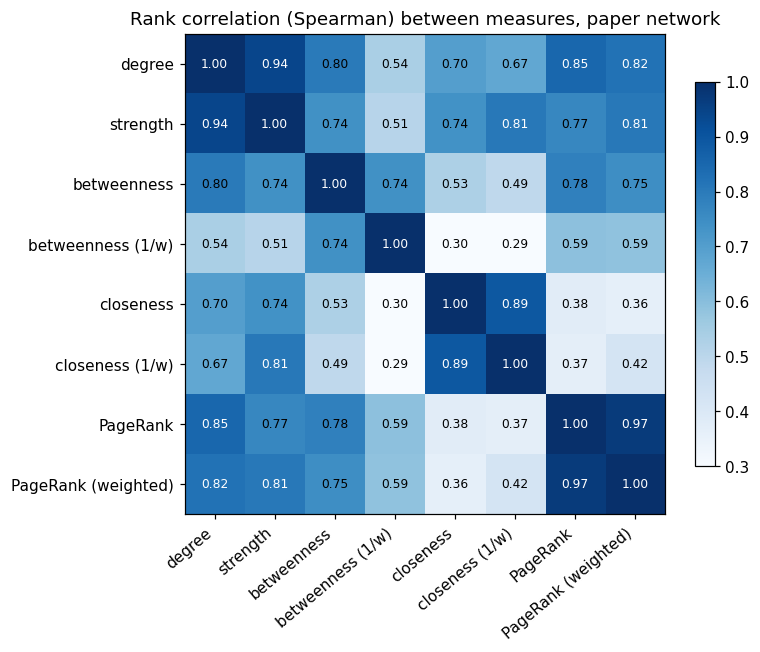

Spearman between the unweighted and weighted version of each measure: {'betweenness': 0.739, 'closeness': 0.892, 'PageRank': 0.969} | degree vs strength: 0.941


In [5]:
def top_nodes(sc, k=10): return sorted(sc, key=sc.get, reverse=True)[:k]

M = {"degree": deg, "strength": strength,
     "betweenness": nx.betweenness_centrality(G), "betweenness (1/w)": nx.betweenness_centrality(G, weight="inv"),
     "closeness": nx.closeness_centrality(G), "closeness (1/w)": nx.closeness_centrality(G, distance="inv"),
     "PageRank": nx.pagerank(G, weight=None), "PageRank (weighted)": nx.pagerank(G, weight="weight")}
top10 = pd.DataFrame({k: top_nodes(v) for k, v in M.items()}); top10.index = range(1, 11); top10.index.name = "rank"
display(top10)

names = list(M)
corr = pd.DataFrame([[spearmanr([M[a][n] for n in nodes], [M[b][n] for n in nodes]).statistic for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(corr.values, cmap="Blues", vmin=0.3, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=40, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if corr.values[i, j] > 0.8 else "black")
ax.set_title("Rank correlation (Spearman) between measures, paper network"); ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
print("Spearman between the unweighted and weighted version of each measure:",
      {m: round(corr.loc[m, f"{m} (1/w)" if m in ("betweenness", "closeness") else f"{m} (weighted)"], 3) for m in ("betweenness", "closeness", "PageRank")},
      "| degree vs strength:", round(corr.loc["degree", "strength"], 3))

**Reading this.** Most measures agree broadly (the big hubs come out on top whatever you use), but there are differences:
- **Degree and strength** agree closely (Spearman 0.94): the top 5 differ only in that strength has LAX where degree has MSP, and swaps DFW and DEN.
- **Betweenness is the sensitive one**: the unweighted top is ANC, but weighting by 1/w puts **ATL first** and ANC second, and the rank correlation between the two betweenness versions is only **0.74**, much lower than for closeness (0.89) or PageRank (0.97).
- Closeness gains ATL at the top once weights are used; PageRank barely changes.

### B2. The betweenness question in detail
The paper's headline structural finding (M1) is that **ANC** is the most central airport by betweenness. Here is how that depends on the weighting.

betweenness version,top 1,top 6
"paper network, unweighted",ANC,"ANC, DEN, ORD, SEA, ATL, MSP"
"paper network, 1/w weighted",ATL,"ATL, ANC, SEA, DEN, LAX, ORD"
"operated-only, unweighted",ANC,"ANC, LAS, DEN, DFW, SEA, ATL"
"operated-only, 1/w weighted",ANC,"ANC, ORD, DFW, PHX, DEN, LAS"


biggest rank gains under 1/w weighting (positive = moves up):


airport,rank unweighted,rank weighted,change
UNK,47,14,33
CVG,52,27,25
KTN,30,11,19
GAL,51,36,15
PHL,25,13,12
LAX,12,5,7
MCG,46,39,7


biggest rank losses:


airport,rank unweighted,rank weighted,change
DCA,34,77,-43
PDX,24,49,-25
IAH,21,39,-18
MCO,35,50,-15
MDW,40,54,-14
DTW,18,32,-14
LAS,10,24,-14


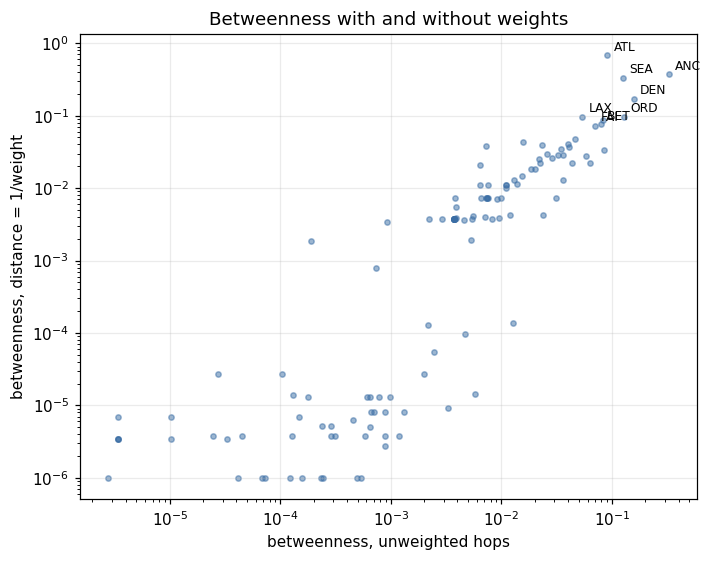

In [6]:
Mop = {"betweenness": nx.betweenness_centrality(Gop), "betweenness (1/w)": nx.betweenness_centrality(Gop, weight="inv"),
       "strength": dict(Gop.degree(weight="weight")), "degree": dict(Gop.degree())}
rows = []
for label, d_ in [("paper network, unweighted", M["betweenness"]), ("paper network, 1/w weighted", M["betweenness (1/w)"]),
                  ("operated-only, unweighted", Mop["betweenness"]), ("operated-only, 1/w weighted", Mop["betweenness (1/w)"])]:
    t = top_nodes(d_, 6); rows.append({"betweenness version": label, "top 1": t[0], "top 6": ", ".join(t)})
display(pd.DataFrame(rows).style.hide(axis="index"))

b_u, b_w = M["betweenness"], M["betweenness (1/w)"]
r_u = pd.Series(b_u).rank(ascending=False, method="min"); r_w = pd.Series(b_w).rank(ascending=False, method="min")
mov = pd.DataFrame({"airport": nodes, "rank unweighted": r_u.values.astype(int), "rank weighted": r_w.values.astype(int)}); mov["change"] = mov["rank unweighted"] - mov["rank weighted"]
mov = mov[(mov["rank unweighted"] <= 40) | (mov["rank weighted"] <= 40)]
print("biggest rank gains under 1/w weighting (positive = moves up):"); display(mov.sort_values("change", ascending=False).head(7).style.hide(axis="index"))
print("biggest rank losses:"); display(mov.sort_values("change").head(7).style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(6.6, 5.2))
mk = [n for n in nodes if b_u[n] > 0 and b_w[n] > 0]
ax.scatter([b_u[n] for n in mk], [b_w[n] for n in mk], s=12, alpha=0.5, color=BLUE)
for n in ["ANC", "ATL", "SEA", "DEN", "ORD", "BET", "LAX", "FAI"]: ax.annotate(n, (b_u[n], b_w[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("betweenness, unweighted hops"); ax.set_ylabel("betweenness, distance = 1/weight"); ax.set_title("Betweenness with and without weights")
plt.tight_layout(); plt.show()

**Reading this.**
- On the paper's own weights, **ANC loses its first place to ATL** once weights are used: weighted shortest paths prefer heavy (hub-to-hub) edges, so more of them pass through ATL. The airports that gain most in rank are mid-sized hubs on heavy corridors (PHL, CVG, LAX) and a few Alaskan gateways (UNK, KTN); those that lose most are airports with many but light routes (DCA, PDX, IAH, MCO, MDW, LAS).
- On the **operated-only** network, ANC is first under **both** versions. So "ANC is the most central airport" is robust to the codeshare caveat but **not** to the choice of weighting on the paper's weights, which are inflated for alliance hubs: this headline is partly a property of treating all edges as equal.
- The sensitivity makes sense: ANC is central because it is the *gateway* to a region (a structural position that the hop-count version sees), while ATL carries the most listed *volume* (what the weighted version sees; M8 confirms that ATL really is the busiest airport, although its listed weight is inflated by Delta's partners).

### B3. Weighted paths take a different route
With heavy edges shorter, shortest paths detour through hubs. We compare, for every airport pair, the number of hops on the weighted shortest path with the minimum number of hops.

In [7]:
hop = dict(nx.all_pairs_shortest_path_length(G))
paths = dict(nx.all_pairs_dijkstra_path(G, weight="inv"))
extra, wl = [], []
for i, u in enumerate(nodes):
    for v in nodes[i + 1:]:
        extra.append(len(paths[u][v]) - 1 - hop[u][v])
extra = np.array(extra)
wlen = dict(nx.all_pairs_dijkstra_path_length(G, weight="inv"))
wavg = np.mean([wlen[u][v] for i, u in enumerate(nodes) for v in nodes[i + 1:]])
print(f"mean hops of the unweighted shortest path : {np.mean([hop[u][v] for i, u in enumerate(nodes) for v in nodes[i + 1:]]):.2f}")
print(f"mean hops of the 1/w-weighted shortest path: {np.mean(extra) + np.mean([hop[u][v] for i, u in enumerate(nodes) for v in nodes[i + 1:]]):.2f}")
print(f"airport pairs for which the weighted route has extra hops: {(extra > 0).mean():.0%} (by 1 hop: {(extra == 1).mean():.0%}, 2: {(extra == 2).mean():.0%}, 3 or more: {(extra >= 3).mean():.0%})")
print(f"average weighted distance (units of 1/route-rows): {wavg:.2f}")

cu = nx.average_clustering(G); cb = np.mean(list(wt.barrat_clustering(G).values())); co = nx.average_clustering(G, weight="weight")
print(f"\nclustering: unweighted {cu:.3f} | Barrat weighted {cb:.3f} | Onnela weighted (networkx) {co:.3f}")

mean hops of the unweighted shortest path : 3.20
mean hops of the 1/w-weighted shortest path: 3.83
airport pairs for which the weighted route has extra hops: 57% (by 1 hop: 51%, 2: 6%, 3 or more: 0%)
average weighted distance (units of 1/route-rows): 0.98

clustering: unweighted 0.494 | Barrat weighted 0.508 | Onnela weighted (networkx) 0.046


**Reading this.** Weighted shortest paths are longer in hops (about 3.8 hops on average, against 3.2): the heavy hub-to-hub edges are "cheap", so the weighted route often takes a detour through a hub even when a more direct path exists. 57% of all airport pairs get at least one extra hop (51% exactly one). For clustering, the Barrat weighted coefficient (0.51) is nearly the same as the unweighted one (0.49), so weights do not change the clustering story of M4. (networkx's `clustering(weight=...)` is Onnela's version, which is scaled by the largest weight and so comes out far smaller (0.05); it is not comparable with the unweighted number, and we do not use it.)

## Part C. Weighted attacks
The paper's attacks remove airports ranked by unweighted measures and count airports in the largest component. Two improvements:
- **Weighted strategies:** rank by strength, by weighted betweenness, by weighted PageRank, under both weightings.
- **A service-based damage measure:** the fraction of the network's total weight (route listings) that is still inside the largest connected component. Removing a hub destroys all its edges, so the weight lost is much larger than the airport count suggests.

The attacked network is always the paper network `G`; the rankings come from each weighting. Airports absent from `G_op` get the lowest rank in operated-only rankings.

In [8]:
pos_idx = {n: i for i, n in enumerate(nodes)}
def order_from(score):
    return sorted(nodes, key=lambda n: (-score.get(n, -1.0), pos_idx[n]))

pr_w_op = nx.pagerank(Gop, weight="weight")
strategies = {
    "degree (unweighted)": order_from(deg),
    "betweenness (unweighted)": order_from(M["betweenness"]),
    "strength (paper weights)": order_from(strength),
    "betweenness 1/w (paper weights)": order_from(M["betweenness (1/w)"]),
    "PageRank weighted (paper weights)": order_from(M["PageRank (weighted)"]),
    "strength (operated weights)": order_from(Mop["strength"]),
    "betweenness 1/w (operated weights)": order_from(Mop["betweenness (1/w)"]),
}
scol = {"degree (unweighted)": BLUE, "betweenness (unweighted)": RED, "strength (paper weights)": ORANGE, "betweenness 1/w (paper weights)": PURPLE,
        "PageRank weighted (paper weights)": TEAL, "strength (operated weights)": BROWN, "betweenness 1/w (operated weights)": GREEN}

cur = {}
for name, o in strategies.items():
    l, lw_, sw_ = wt.service_percolation(G, o)
    cur[name] = {"lcc": l, "service": lw_ / W_all, "surv": sw_ / W_all}
rl, rs = [], []
for _ in range(100):
    l, lw_, sw_ = wt.service_percolation(G, list(rng.permutation(nodes))); rl.append(l); rs.append(lw_ / W_all)
cur["random (mean of 100)"] = {"lcc": np.mean(rl, axis=0), "service": np.mean(rs, axis=0)}

def row(name):
    c = cur[name]; lcc = c["lcc"]; sv = c["service"]
    return {"strategy": name, "R (airports in LCC)": at.robustness_R(lcc, N), "k50 airports": at.k_to_reach(lcc, N, .5),
            "k50 service": next((k for k in range(N + 1) if sv[k] <= 0.5), None),
            "LCC after 10": int(round(lcc[10])), "service in LCC after 5": sv[5], "after 10": sv[10], "after 20": sv[20]}
ct = pd.DataFrame([row(n) for n in cur]).sort_values("R (airports in LCC)")
ct.style.hide(axis="index").format({"R (airports in LCC)": "{:.3f}", "service in LCC after 5": "{:.2f}", "after 10": "{:.2f}", "after 20": "{:.2f}"})

strategy,R (airports in LCC),k50 airports,k50 service,LCC after 10,service in LCC after 5,after 10,after 20
PageRank weighted (paper weights),0.054,17,9,354,0.62,0.44,0.23
betweenness (unweighted),0.061,19,12,333,0.66,0.53,0.33
degree (unweighted),0.062,35,10,426,0.64,0.48,0.25
strength (operated weights),0.068,33,9,450,0.63,0.45,0.25
strength (paper weights),0.073,41,9,437,0.62,0.44,0.24
betweenness 1/w (paper weights),0.105,24,13,334,0.67,0.52,0.39
betweenness 1/w (operated weights),0.129,31,9,342,0.73,0.46,0.33
random (mean of 100),0.387,190,158,525,0.98,0.96,0.93


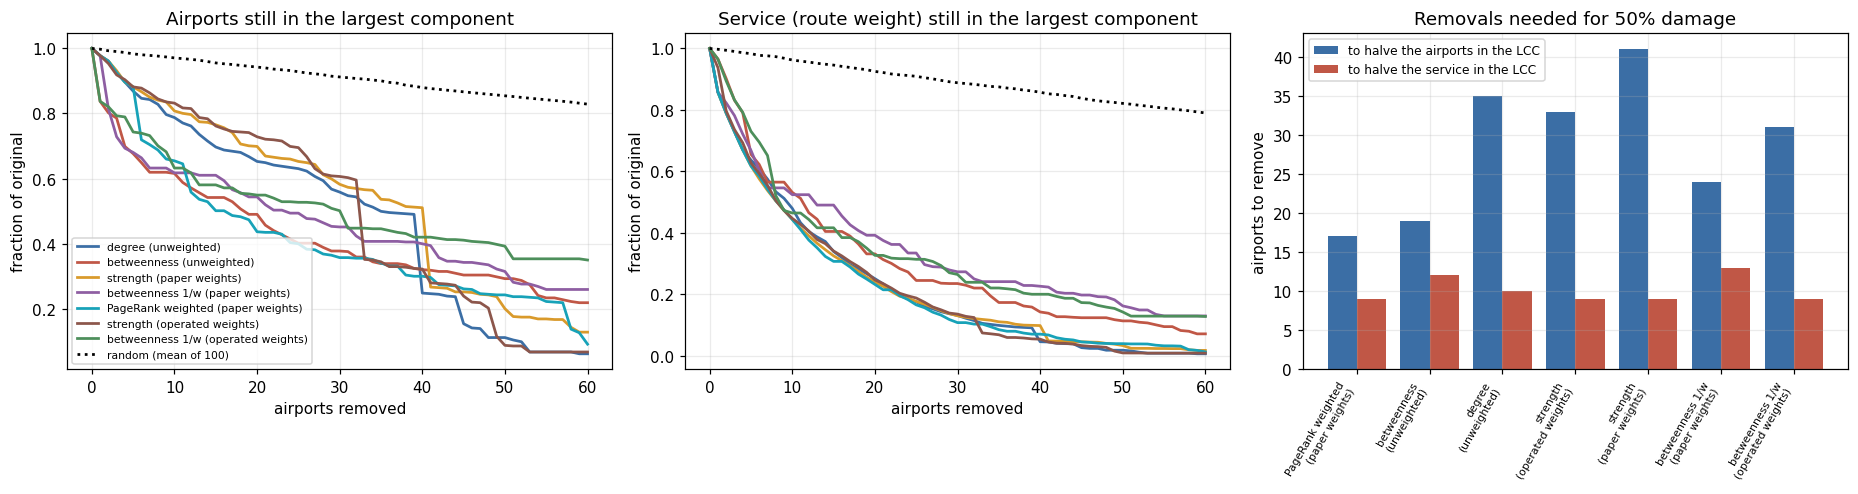

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
K = 60
for name in cur:
    c = cur[name]; col_ = scol.get(name, "black"); ls = ":" if name.startswith("random") else "-"
    axes[0].plot(range(K + 1), c["lcc"][:K + 1] / N, color=col_, ls=ls, lw=1.8, label=name)
    axes[1].plot(range(K + 1), c["service"][:K + 1], color=col_, ls=ls, lw=1.8, label=name)
axes[0].set_title("Airports still in the largest component"); axes[1].set_title("Service (route weight) still in the largest component")
for ax in axes[:2]: ax.set_xlabel("airports removed"); ax.set_ylabel("fraction of original")
axes[0].legend(fontsize=7)
sc_ = ct[~ct.strategy.str.startswith("random")]
x = np.arange(len(sc_)); w_ = 0.4
axes[2].bar(x - w_ / 2, sc_["k50 airports"], w_, color=BLUE, label="to halve the airports in the LCC"); axes[2].bar(x + w_ / 2, sc_["k50 service"], w_, color=RED, label="to halve the service in the LCC")
axes[2].set_xticks(x); axes[2].set_xticklabels([s.replace(" (", "\n(") for s in sc_.strategy], rotation=60, ha="right", fontsize=7); axes[2].set_ylabel("airports to remove"); axes[2].set_title("Removals needed for 50% damage"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading this.**
- **Service is far more concentrated than airports.** Removing the top 10 airports by strength leaves 437 of 541 airports (81%) in the largest component, but only **44% of the route weight**. The airport-count LCC understates the real damage, as suggested for efficiency in M5.
- **Halving the service takes far fewer removals than halving the airports:** 9 to 13 airports for service, against 17 to 41 for airport counts (right panel). The largest airports carry a disproportionate share of the weight. (Random removal needs 158 vs 190.)
- **The ranking of strategies depends on what is measured.** For airport counts, weighted PageRank and the unweighted betweenness attack are the most damaging (R 0.054 and 0.061). For service, the strength-based and PageRank attacks are the most damaging (about a quarter of the service left after 20 removals), unweighted degree is nearly as good, and unweighted betweenness leaves a third (0.33). The paper's choice (betweenness, judged by airport counts) is a different attacker from the one that destroys service.
- **Weighted betweenness (1/w) is the *least* damaging targeted strategy** (R 0.105 and 0.129, service left after 20: 0.39 and 0.33): it ranks heavy hubs highly but misses the Alaskan gateways (ANC, SEA) that make unweighted betweenness effective in M5. The gateway effect is a property of the hop-count structure.
- **The choice of weighting for the ranking matters little for strength-based attacks** (R 0.068 with operated weights vs 0.073 with the paper's; service left after 20: 0.25 vs 0.24), so those results are robust to the codeshare caveat; for weighted betweenness the two differ more (R 0.129 vs 0.105).

## Part D. Do the paper's conclusions survive on the operated-only network?
The operated-only network `G_op` removes the 26% of edges that rest on codeshare listings alone (and 95 small airports). If the paper's findings are real properties of air travel, and not artefacts of how OpenFlights records codeshares, they should hold on `G_op` too. We recompute the key result of every milestone.

In [10]:
def profile(g, label, n_boot=300, seed=1):
    gn = list(g.nodes); n = len(gn); m = g.number_of_edges(); dg = dict(g.degree())
    out = {"airports": n, "edges": m}
    met = nm.fast_metrics(g)
    out.update({"average degree": 2 * m / n, "largest hub": f"{max(dg, key=dg.get)} ({max(dg.values())})", "clustering C": met["C"], "path length L": met["L"],
                "diameter": met["diameter"], "assortativity": met["assortativity"], "share of degree-1 airports": met["share_degree1"]})
    b = nx.betweenness_centrality(g); out["top betweenness"] = ", ".join(top_nodes(b, 3))
    x = np.array([dg[v] for v in gn]); f = pt.fit(x, "discrete"); out["power-law gamma (discrete MLE)"] = f["alpha"]; out["gamma x_min"] = int(f["xmin"])
    out["power-law goodness-of-fit p"] = pt.gof_bootstrap(x, "discrete", n_boot=n_boot, seed=seed)["p"]
    # communities
    Gu = nx.Graph(g.edges); qs = [cm.louvain(Gu, s, weight=None) for s in range(30)]
    out["Louvain communities (median)"] = float(np.median([len(c) for c in qs])); out["Louvain modularity (unweighted)"] = float(np.mean([nx.community.modularity(Gu, c, weight=None) for c in qs]))
    # clustering excess explained by degrees
    dpC = np.mean([nm.fast_metrics(nm.degree_preserving(Gu, 900 + s))["C"] for s in range(30)]); erC = np.mean([nm.fast_metrics(nm.er_like(n, m, 900 + s))["C"] for s in range(30)])
    out["share of clustering excess explained by degrees"] = (dpC - erC) / (met["C"] - erC)
    # attacks
    best = {}
    for nm_ in ["degree", "betweenness", "closeness", "pagerank"]:
        o = at.static_order(g, nm_); lc, _, _ = at.percolation_curves(g, o); best[nm_] = lc
    rl = np.mean([at.percolation_curves(g, list(rng.permutation(gn)))[0] for _ in range(100)], axis=0)
    out["LCC share after removing 5 by betweenness"] = best["betweenness"][5] / n; out["LCC share after removing 5 by degree"] = best["degree"][5] / n
    out["removals to halve the LCC: random"] = at.k_to_reach(rl, n, .5) / n; out["removals to halve the LCC: best targeted"] = min(at.k_to_reach(v, n, .5) for v in best.values()) / n
    # cascade
    C_ = cs.Cascade(g); hub = int(np.argmax(C_.deg)); tg = np.round(np.arange(0.05, 0.4001, 0.005), 3)
    full = [t for t in tg if C_.run([hub], C_.need(t))[0].sum() >= 0.5 * n]; out["hub cascade: critical threshold"] = max(full) if full else 0.0
    tcs = []
    for i in range(n):
        ok = [t for t in tg if C_.run([i], C_.need(t))[0].sum() >= 0.5 * n]; tcs.append(max(ok) if ok else 0.0)
    out["worst origin: critical threshold"] = max(tcs); out["worst origin"] = C_.nodes[int(np.argmax(tcs))]
    return out, best, rl, f, x

prof_all, curves_all, rl_all, fit_all, x_all = profile(G, "paper network")
prof_op, curves_op, rl_op, fit_op, x_op = profile(Gop, "operated-only")
prof = pd.DataFrame({"paper network G": prof_all, "operated-only G_op": prof_op})
def fmt(v): return f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v)
prof.map(fmt)

,paper network G,operated-only G_op
airports,541,446
edges,2780,2065
average degree,10.277,9.260
largest hub,ATL (153),ATL (124)
clustering C,0.494,0.407
path length L,3.200,3.280
diameter,7,7
assortativity,-0.341,-0.278
share of degree-1 airports,0.285,0.325
top betweenness,"ANC, DEN, ORD","ANC, LAS, DEN"


agreement of the communities of the two networks on their 446 common airports: NMI = 0.67 (weighted Louvain), 0.61 (unweighted Louvain)


setting,Alaskan airports,runs (of 30) in which the ANC community is exactly Alaska,runs in which it contains no non-Alaskan airport
"paper network, weighted Louvain",131,21,30
"paper network, unweighted Louvain",131,0,30
"operated-only, weighted Louvain",116,7,30
"operated-only, unweighted Louvain",116,0,30


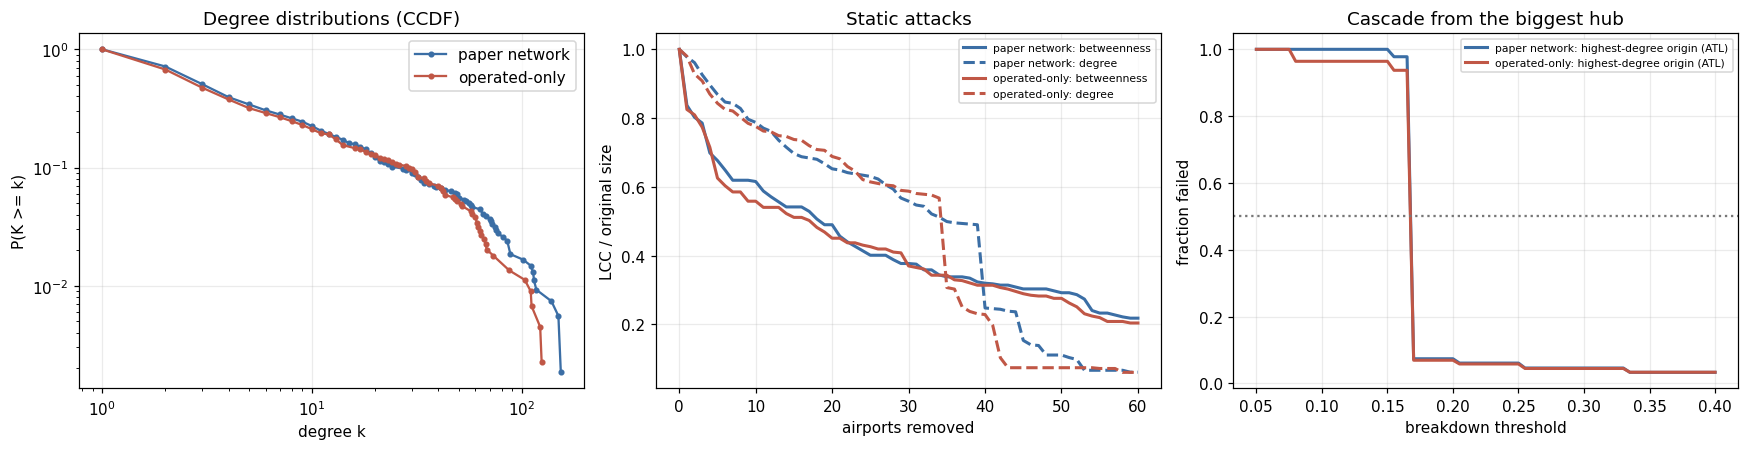

In [11]:
def louvain_pair(g, weight, seeds):
    return [cm.louvain(g, sd, weight=weight) for sd in seeds]

def best_of(g, weight, seeds=range(20)):
    parts = louvain_pair(g, weight, seeds); gu = g if weight else nx.Graph(g.edges)
    return max(parts, key=lambda c: nx.community.modularity(gu, c, weight=weight))

common = list(Gop.nodes)
best_w_all, best_w_op = best_of(G, "weight"), best_of(Gop, "weight")
best_u_all, best_u_op = best_of(G, None), best_of(Gop, None)
nmi_w = nmi(cm.labels(best_w_all, common), cm.labels(best_w_op, common)); nmi_u = nmi(cm.labels(best_u_all, common), cm.labels(best_u_op, common))
print(f"agreement of the communities of the two networks on their {len(common)} common airports: NMI = {nmi_w:.2f} (weighted Louvain), {nmi_u:.2f} (unweighted Louvain)")

def alaska_exact(g, weight, seeds=range(30)):
    A = {n for n in g if pos[n][1] > 50}
    exact = pure = 0
    for sd in seeds:
        c = next(c for c in cm.louvain(g, sd, weight=weight) if "ANC" in c)
        exact += (c == A); pure += c <= A                       # pure: the community contains no mainland or Hawaiian airport
    return exact, pure, len(A)
rows = []
for lab, g, wkey in [("paper network, weighted Louvain", G, "weight"), ("paper network, unweighted Louvain", G, None), ("operated-only, weighted Louvain", Gop, "weight"), ("operated-only, unweighted Louvain", Gop, None)]:
    ex, pu, nA = alaska_exact(g, wkey); rows.append({"setting": lab, "Alaskan airports": nA, "runs (of 30) in which the ANC community is exactly Alaska": ex, "runs in which it contains no non-Alaskan airport": pu})
display(pd.DataFrame(rows).style.hide(axis="index"))
alaska_w_all, alaska_w_op = rows[0]["runs (of 30) in which the ANC community is exactly Alaska"], rows[2]["runs (of 30) in which the ANC community is exactly Alaska"]
assert all(r["runs in which it contains no non-Alaskan airport"] == 30 for r in rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
for x_, lab, c in [(x_all, "paper network", BLUE), (x_op, "operated-only", RED)]:
    ks = np.sort(np.unique(x_)); ccdf = [(x_ >= k).mean() for k in ks]; ax.loglog(ks, ccdf, "o-", ms=3, color=c, label=lab)
ax.set_xlabel("degree k"); ax.set_ylabel("P(K >= k)"); ax.set_title("Degree distributions (CCDF)"); ax.legend()
ax = axes[1]
for lab, cu_, c in [("paper network", curves_all, BLUE), ("operated-only", curves_op, RED)]:
    nn_ = N if lab == "paper network" else Gop.number_of_nodes()
    ax.plot(range(61), cu_["betweenness"][:61] / nn_, color=c, lw=2, label=f"{lab}: betweenness"); ax.plot(range(61), cu_["degree"][:61] / nn_, color=c, lw=2, ls="--", label=f"{lab}: degree")
ax.set_xlabel("airports removed"); ax.set_ylabel("LCC / original size"); ax.set_title("Static attacks"); ax.legend(fontsize=7)
ax = axes[2]
for lab, g, c in [("paper network", G, BLUE), ("operated-only", Gop, RED)]:
    C_ = cs.Cascade(g); hub = int(np.argmax(C_.deg)); tg = np.round(np.arange(0.05, 0.4001, 0.005), 3)
    ax.plot(tg, [C_.run([hub], C_.need(t))[0].mean() for t in tg], color=c, lw=2, label=f"{lab}: highest-degree origin ({C_.nodes[hub]})")
ax.axhline(0.5, color=GREY, ls=":"); ax.set_xlabel("breakdown threshold"); ax.set_ylabel("fraction failed"); ax.set_title("Cascade from the biggest hub"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading the comparison.** Almost everything carries over:
- **Structure (M1):** the operated-only network is still hub-and-spoke: path length 3.28 vs 3.20, diameter 7 in both, strongly negative degree assortativity (-0.28 vs -0.34), clustering lower (0.41 vs 0.49), and the same top-betweenness airport (ANC).
- **Heavy tail (M2):** the discrete power-law exponent is **identical** (1.73 in both, x_min 2), and a pure power law is **rejected on both** networks (goodness-of-fit p below 0.01).
- **Communities (M3):** both networks give a median of 8 Louvain communities and the same modularity (0.35 unweighted). The partitions agree moderately on the airports they share (NMI 0.67 with weighted Louvain, 0.61 unweighted). The "Alaska is exactly one community" result is **less robust**: it is a property of the *weighted* Louvain of the paper's setting and holds in 21 of 30 runs on the paper network but only 7 of 30 on the operated-only network (where 15 small Alaskan airports are missing), and in 0 of 30 with unweighted Louvain on either network, which splits Alaska into two or more communities. What is robust is that the community of ANC **never contains a mainland airport**: Alaska is always a separate region, even if it is sometimes subdivided.
- **Clustering vs degrees (M4):** the degree sequence explains 86% of the clustering excess on the paper network and 87% on the operated-only one.
- **Attacks (M5):** random removal needs about 35% of airports removed to halve the LCC on both, targeted removal only 3%; betweenness is again the quickest to cut the network at the start (after 5 removals the LCC is 68% vs 63% of the airports).
- **Cascade (M6):** the cliff is at the same place (hub critical threshold 0.165 on both) and the worst origin is LAS on both (critical threshold 0.20). That the thresholds coincide is not an accident: the cascade thresholds are quantised at fractions 1/k of small degrees (1/6 and 1/5), which depend on the many small airports, and both networks have them.

So the paper's qualitative conclusions, and even several specific numbers, are **robust to the codeshare problem**.

## Part E. Verdict

In [12]:
vd = pd.DataFrame([
    ("(paper) the weights are built but not used",
     f"Confirmed (M1). Using them changes rankings noticeably for betweenness: the top airport on the paper's weights is {top_nodes(M['betweenness (1/w)'], 1)[0]} instead of ANC", "gap confirmed"),
    ("(paper) edge weight = number of flights",
     f"It is the number of airline listings. Codeshare rows are {1 - W_op / W_all:.0%} of the total; ATL's weight is {cshare['ATL']:.0%} codeshare; DFW has more operated routes than ATL", "weakness"),
    ("Hub-and-spoke structure and the main structural findings",
     f"Robust: operated-only network keeps the same character (L {prof_op['path length L']:.2f} vs {prof_all['path length L']:.2f}, diameter {prof_op['diameter']} vs {prof_all['diameter']}, top betweenness {prof_op['top betweenness'].split(',')[0]})", "robust to weighting"),
    ("Which airport is most critical",
     "Depends on the definition: ANC (hop-count betweenness, both weightings), ATL (weighted betweenness and strength on the paper's weights, which codeshare inflates), DFW (strength on operated weights)", "definition-dependent"),
    ("Robust to random failure, fragile to targeted attack",
     f"Holds on both networks; in service units the damage from targeted attacks is larger than the airport count suggests (10 removals by strength leave {cur['strength (paper weights)']['service'][10]:.0%} of the service in the main network)", "robust, understated by airport counts"),
    ("Cascade cliff and the specific threshold 0.165",
     f"Same on both networks: hub critical threshold {prof_op['hub cascade: critical threshold']:.3f} (operated) vs {prof_all['hub cascade: critical threshold']:.3f}; worst origin {prof_op['worst origin']} vs {prof_all['worst origin']}", "robust to the codeshare check"),
], columns=["question", "what we find", "status"])
vd.style.hide(axis="index").format(escape="html").set_properties(subset=["question", "what we find"], **{"text-align": "left", "white-space": "normal"})

question,what we find,status
(paper) the weights are built but not used,Confirmed (M1). Using them changes rankings noticeably for betweenness: the top airport on the paper's weights is ATL instead of ANC,gap confirmed
(paper) edge weight = number of flights,It is the number of airline listings. Codeshare rows are 44% of the total; ATL's weight is 72% codeshare; DFW has more operated routes than ATL,weakness
Hub-and-spoke structure and the main structural findings,"Robust: operated-only network keeps the same character (L 3.28 vs 3.20, diameter 7 vs 7, top betweenness ANC)",robust to weighting
Which airport is most critical,"Depends on the definition: ANC (hop-count betweenness, both weightings), ATL (weighted betweenness and strength on the paper's weights, which codeshare inflates), DFW (strength on operated weights)",definition-dependent
"Robust to random failure, fragile to targeted attack",Holds on both networks; in service units the damage from targeted attacks is larger than the airport count suggests (10 removals by strength leave 44% of the service in the main network),"robust, understated by airport counts"
Cascade cliff and the specific threshold 0.165,Same on both networks: hub critical threshold 0.165 (operated) vs 0.165; worst origin LAS vs LAS,robust to the codeshare check


## Checks

In [13]:
assert (Gop.number_of_nodes(), Gop.number_of_edges()) == (446, 2065) and W_all == 10507
assert nx.is_connected(Gop) and len(lost) == 95
# strength-degree scaling above 1, disparity above 1 at hubs
assert 1.05 < beta < 1.25 and np.median(y2k[d >= 50]) > 1
# codeshare inflation
assert cshare["ATL"] > 0.7 and tab.set_index("airport").loc["DFW", "strength (operated)"] > tab.set_index("airport").loc["ATL", "strength (operated)"]
# ranking sensitivity: ANC top unweighted, ATL top on the paper's weights; ANC top on operated network under both
assert top_nodes(M["betweenness"], 1) == ["ANC"] and top_nodes(M["betweenness (1/w)"], 1) == ["ATL"]
assert top_nodes(Mop["betweenness"], 1) == ["ANC"] and top_nodes(Mop["betweenness (1/w)"], 1) == ["ANC"]
assert corr.loc["betweenness", "betweenness (1/w)"] < corr.loc["degree", "strength"]
# weighted shortest paths use more hops
assert np.mean(extra) > 0.4 and abs(cb - cu) < 0.05 and co < 0.1
# service-weighted percolation: service lost faster than airports for the strongest attack
c_ = cur["strength (paper weights)"]; assert c_["service"][10] < c_["lcc"][10] / N
assert at.robustness_R(cur["strength (paper weights)"]["lcc"], N) < at.robustness_R(cur["random (mean of 100)"]["lcc"], N) / 3
# robustness on the operated-only network
assert prof_op["share of degree-1 airports"] > 0.2 and prof_op["top betweenness"].startswith("ANC") and prof_op["diameter"] == 7
assert prof_op["removals to halve the LCC: random"] > 3 * prof_op["removals to halve the LCC: best targeted"]
assert prof_op["share of clustering excess explained by degrees"] > 0.6 and nmi_w > 0.5
assert prof_op["hub cascade: critical threshold"] == prof_all["hub cascade: critical threshold"] == 0.165 and prof_op["worst origin"] == prof_all["worst origin"] == "LAS"
assert abs(prof_op["power-law gamma (discrete MLE)"] - prof_all["power-law gamma (discrete MLE)"]) < 0.05 and prof_op["power-law goodness-of-fit p"] < 0.1
assert alaska_w_all >= 15
print("All M7 assertions passed.")

All M7 assertions passed.


## Summary and take-aways

- **The weights were never used, and they should be used with care.** The paper's weight counts airline *listings* per airport pair; 44% of the underlying rows are codeshare listings, 26% of the edges rest on them alone, and ATL's weight is 72% codeshare. So the paper's weights partly reflect airline alliances in the listings (M8 shows that, against real flights, they still rank the major airports well and better than the operated-only weights). We therefore used two weightings, an upper bound (all rows, the paper's) and a lower bound (operated rows only), and trust only what holds on both.
- **Weights add real information:** strength grows faster than degree (exponent about 1.13); heavy edges join big airports; an airport's weight is concentrated on a few links (disparity); weighted shortest paths take about 3.8 hops instead of 3.2 because heavy hub edges are "short".
- **"Which airport is most critical?" depends on the definition:** ANC by hop-count betweenness (on both weightings), ATL by weighted betweenness on the paper's weights, DFW by operated strength. The paper's ANC headline is robust to the codeshare problem but not to the choice of weighting on inflated weights.
- **Service is more concentrated than airports.** Measured in route weight rather than airport counts, targeted removal does much more damage: the airport-count LCC understates it, and the best attack for service is not the best attack for airports.
- **The paper's conclusions survive the codeshare check, even in several specific numbers:** the operated-only network is still hub-and-spoke (L 3.28, diameter 7, ANC top betweenness), has the same power-law exponent (1.73), rejects a pure power law, gives the same number of communities and modularity, has 86% to 87% of its clustering explained by degrees, is robust to random failure and fragile to targeted attack, and has the same cascade cliff (0.165) and worst origin (LAS).
- **Caveats:** the operated-only network is a lower bound (it drops 95 small airports that probably do have service); neither weighting measures passengers. Real traffic is the subject of M8.

**Next:** M8 replaces both weightings with real traffic counts from the BTS on-time file and adds delay propagation.